<a href="https://colab.research.google.com/github/jayy0101/image-pixel-manipulator/blob/main/image_pixel_manipulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Pixel Manipulator (Synthetic Images)
**Create, crop, flip, recolor and filter images using only NumPy**

An image is just a 3D array: `(height, width, 3)` where the last axis holds **R, G, B** values from 0 to 255 (`uint8`).
No image files, no OpenCV, no PIL. Every picture here is built from NumPy arrays.

| Step | What we build |
|---|---|
| 1 | Blank image with `np.zeros`, regions filled with `np.full` |
| 2 | Color blocks and stripes with 3D slicing |
| 3 | Crop, flip (negative-step slicing), extract R/G/B channels |
| 4 | Brighten/darken via `float32`, then cast back to `uint8`; bright-pixel mask |
| 5 | Memory comparison `uint8` vs `float64` with `nbytes` |
| Bonus | Grayscale, normalization (0-1), and simple data augmentation (the ML link) |

## Step 0: Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

def show(images, titles=None, figsize=(14, 4)):
    """Display one or more images side by side."""
    if not isinstance(images, (list, tuple)):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255 if im.dtype == np.uint8 else None)
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Step 1: Blank image with `np.zeros`, regions filled with `np.full`
All zeros means black (R=0, G=0, B=0). `dtype=np.uint8` keeps values in 0-255.

Shape: (200, 200, 3)
Dtype: uint8
ndim : 3 | size: 120000 | pixel [0,0]: [0 0 0]


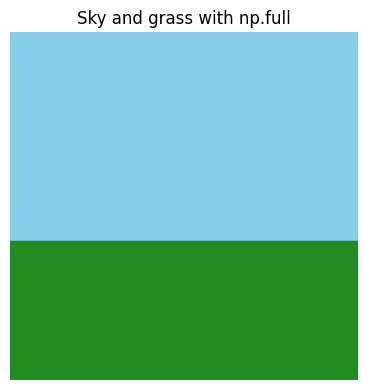

In [ ]:
H, W = 200, 200
img = np.zeros((H, W, 3), dtype=np.uint8)

print("Shape:", img.shape)       # (height, width, channels)
print("Dtype:", img.dtype)
print("ndim :", img.ndim, "| size:", img.size, "| pixel [0,0]:", img[0, 0])

# Fill regions with np.full: sky (top 120 rows) and grass (bottom 80 rows)
img[:120] = np.full((120, W, 3), (135, 206, 235), dtype=np.uint8)   # sky blue
img[120:] = np.full((80, W, 3),  (34, 139, 34),  dtype=np.uint8)    # grass green

show(img, ["Sky and grass with np.full"], figsize=(4, 4))

## Step 2: Color blocks and stripes with 3D slicing
`img[rows, cols, channel]`. Using `:` for the channel axis sets all three colors at once.

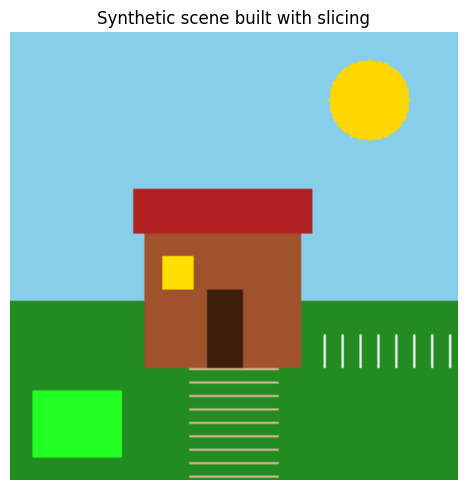

In [ ]:
scene = img.copy()      # copy so Step 1 stays untouched

# House body (brown block) and roof (red), door (dark), window (yellow)
scene[90:150, 60:130] = (160, 82, 45)       # house walls
scene[70:90,  55:135] = (178, 34, 34)       # roof
scene[115:150, 88:104] = (60, 30, 10)       # door
scene[100:115, 68:82]  = (255, 223, 0)      # window

# Fence stripes: every 8th column, using a step in the slice
scene[135:150, 140:200:8] = (255, 255, 255)

# Path stripes on the grass: alternate rows with a step
scene[150:200:6, 80:120] = (210, 180, 140)

# Change ONE channel only: boost green in a patch -> img[r1:r2, c1:c2, 1]
scene[160:190, 10:50, 1] = 255

# Sun: circle via a boolean mask built from coordinate grids
yy, xx = np.ogrid[:H, :W]
sun_mask = (yy - 30) ** 2 + (xx - 160) ** 2 <= 18 ** 2
scene[sun_mask] = (255, 215, 0)

show(scene, ["Synthetic scene built with slicing"], figsize=(5, 5))

## Step 3: Crop, flip and channel extraction

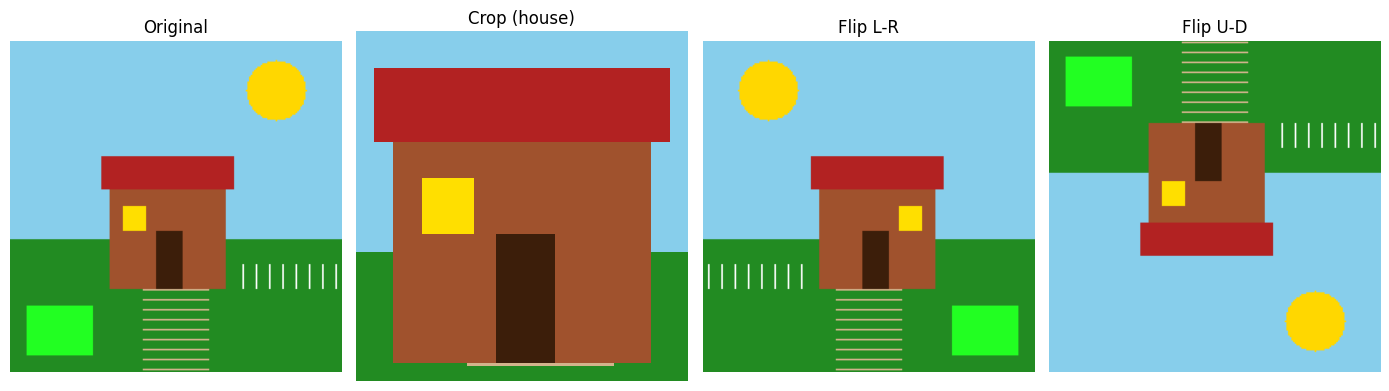

Crop shape: (95, 90, 3)


In [ ]:
# Crop: just slice a region
crop = scene[60:155, 50:140]

# Flips with negative step slicing
flip_lr = scene[:, ::-1]       # mirror left-right
flip_ud = scene[::-1, :]       # mirror up-down
rot_180 = scene[::-1, ::-1]    # both

show([scene, crop, flip_lr, flip_ud], ["Original", "Crop (house)", "Flip L-R", "Flip U-D"])
print("Crop shape:", crop.shape)

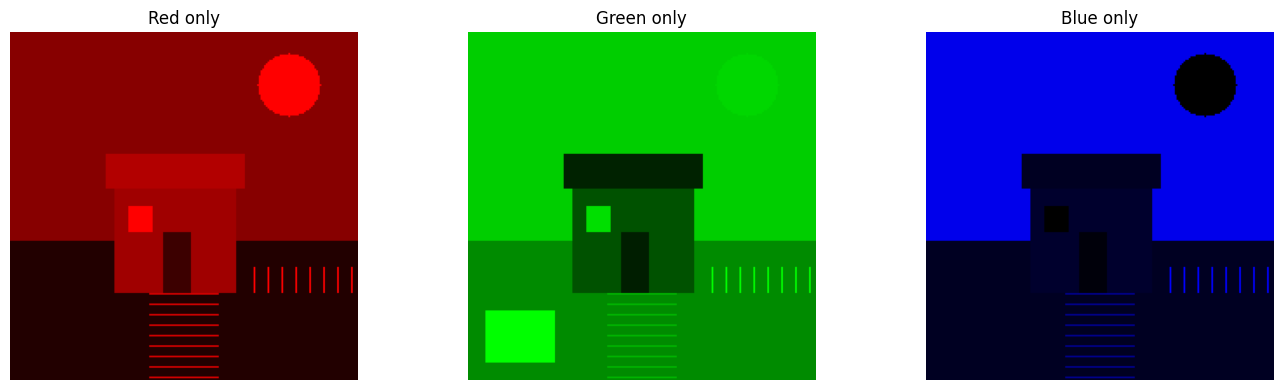

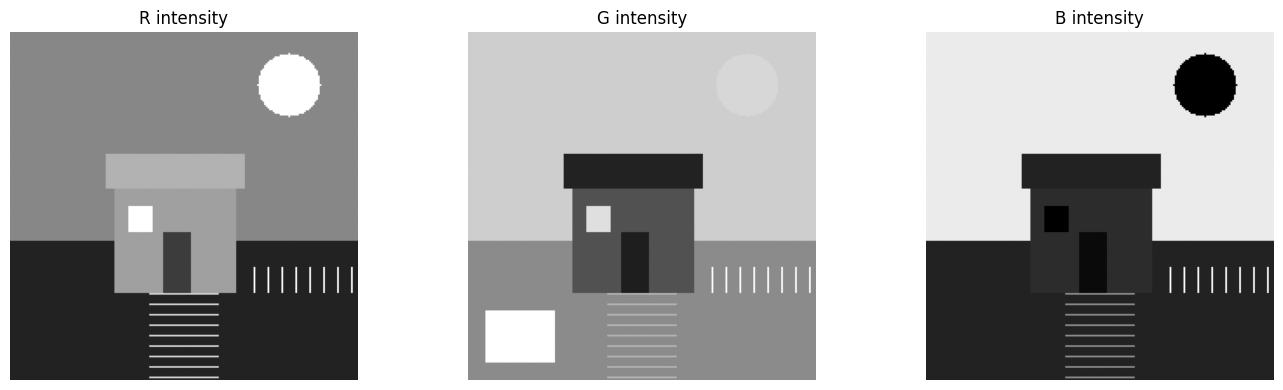

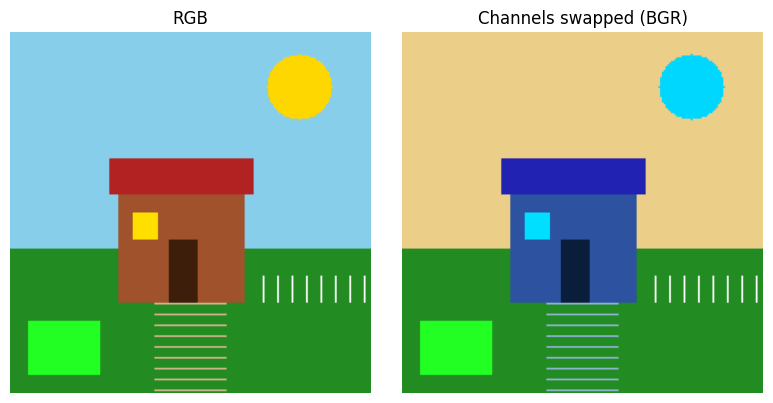

In [ ]:
# Extract single channels (2D arrays). Show as grayscale intensity,
# and as a colored image by zeroing the other channels.
R, G, B = scene[:, :, 0], scene[:, :, 1], scene[:, :, 2]

def only_channel(image, ch):
    out = np.zeros_like(image)
    out[:, :, ch] = image[:, :, ch]
    return out

show([only_channel(scene, 0), only_channel(scene, 1), only_channel(scene, 2)],
     ["Red only", "Green only", "Blue only"])
show([R, G, B], ["R intensity", "G intensity", "B intensity"])

# Swap channels: RGB -> BGR using fancy indexing with a channel index list
bgr = scene[:, :, [2, 1, 0]]
show([scene, bgr], ["RGB", "Channels swapped (BGR)"], figsize=(8, 4))

## Step 4: Brighten / darken with `astype(float32)`, then cast back
**Why float32 first?** `uint8` wraps around: `200 + 100` becomes `44`, not `255`. Do the math in float, `np.clip` to 0-255, then cast back.

uint8: 200 + 100 = [44] (wrapped around!)


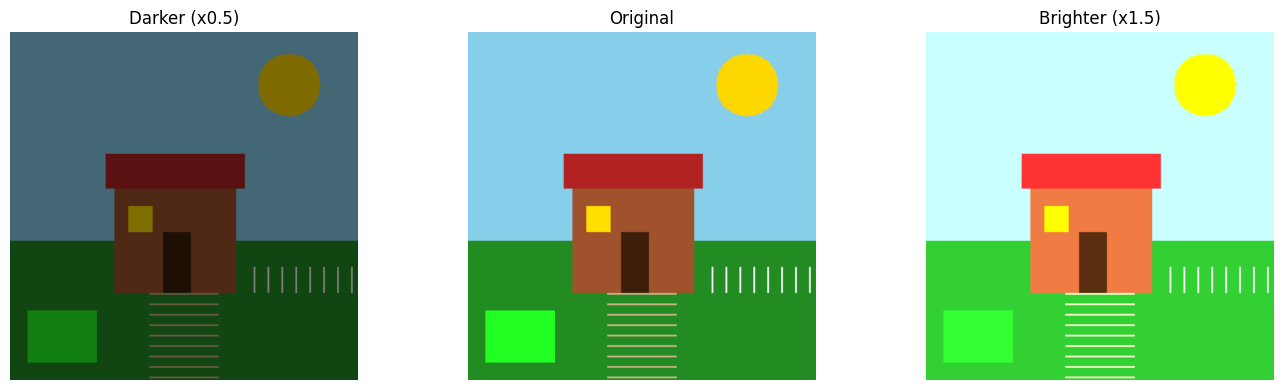

In [ ]:
# The overflow trap
a = np.array([200], dtype=np.uint8)
print("uint8: 200 + 100 =", a + np.uint8(100), "(wrapped around!)")

def adjust_brightness(image, factor):
    f = image.astype(np.float32) * factor          # safe float math
    return np.clip(f, 0, 255).astype(np.uint8)      # clamp, then back to uint8

bright = adjust_brightness(scene, 1.5)
dark   = adjust_brightness(scene, 0.5)
show([dark, scene, bright], ["Darker (x0.5)", "Original", "Brighter (x1.5)"])

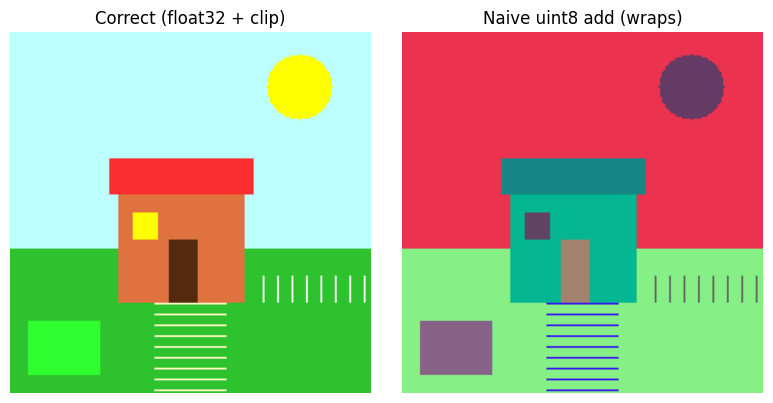

In [ ]:
# Naive brightening WITHOUT float/clip -> wrap-around artifacts
naive = scene + np.uint8(100)
show([adjust_brightness(scene, 1.4), naive], ["Correct (float32 + clip)", "Naive uint8 add (wraps)"], figsize=(8, 4))

Bright pixels: 19411 of 40000 (48.5%)


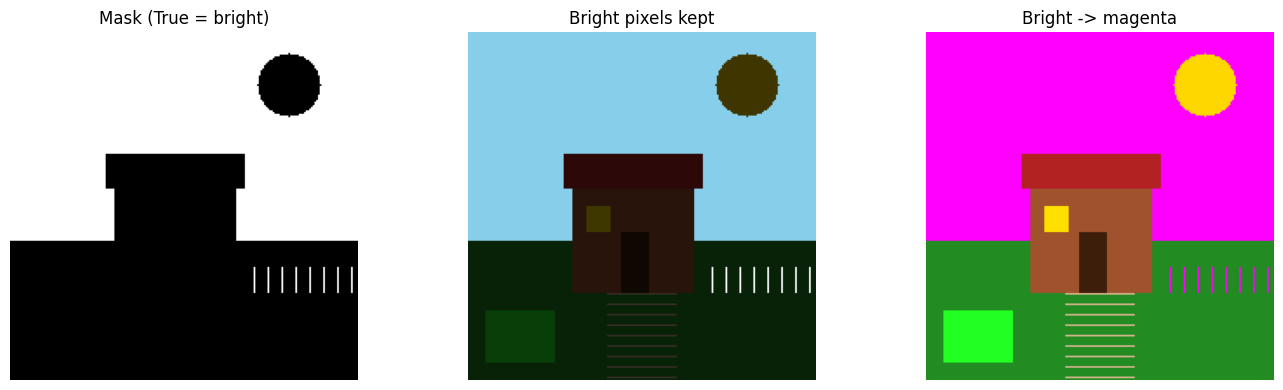

In [ ]:
# Bright-pixel mask: pixel brightness = mean of R, G, B
brightness = scene.astype(np.float32).mean(axis=2)     # (200, 200)
bright_mask = brightness > 180

print(f"Bright pixels: {bright_mask.sum()} of {bright_mask.size} ({bright_mask.mean()*100:.1f}%)")

# Highlight: keep bright pixels, dim everything else
highlight = scene.copy()
highlight[~bright_mask] = (highlight[~bright_mask] * 0.25).astype(np.uint8)

# Recolor: turn all bright pixels magenta
recolor = scene.copy()
recolor[bright_mask] = (255, 0, 255)

show([bright_mask, highlight, recolor], ["Mask (True = bright)", "Bright pixels kept", "Bright -> magenta"])

## Step 5: Memory of `uint8` vs `float32` vs `float64`

dtype       itemsize      nbytes        KB
------------------------------------------
uint8              1     120,000     117.2
float32            4     480,000     468.8
float64            8     960,000     937.5

float64 uses 8x the memory of uint8 for the SAME picture.


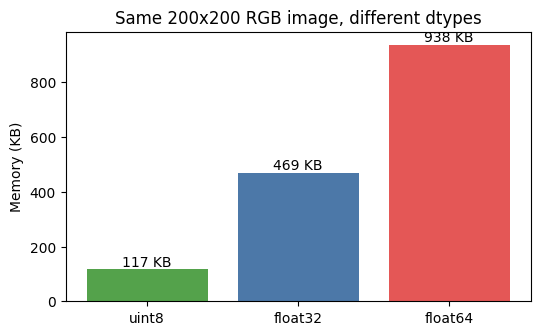

In [ ]:
img_u8  = scene
img_f32 = scene.astype(np.float32) / 255.0
img_f64 = scene.astype(np.float64) / 255.0

print(f"{'dtype':<10}{'itemsize':>10}{'nbytes':>12}{'KB':>10}")
print("-" * 42)
for name, arr in [("uint8", img_u8), ("float32", img_f32), ("float64", img_f64)]:
    print(f"{name:<10}{arr.itemsize:>10}{arr.nbytes:>12,}{arr.nbytes/1024:>10.1f}")

print(f"\nfloat64 uses {img_f64.nbytes // img_u8.nbytes}x the memory of uint8 for the SAME picture.")

fig, ax = plt.subplots(figsize=(6, 3.5))
labels = ["uint8", "float32", "float64"]
sizes = [img_u8.nbytes, img_f32.nbytes, img_f64.nbytes]
ax.bar(labels, [s / 1024 for s in sizes], color=["#54A24B", "#4C78A8", "#E45756"])
ax.set_ylabel("Memory (KB)")
ax.set_title("Same 200x200 RGB image, different dtypes")
for i, s in enumerate(sizes):
    ax.text(i, s / 1024, f"{s/1024:.0f} KB", ha="center", va="bottom")
plt.show()

## Bonus: Where this meets Machine Learning
ML models never see "pictures", they see **float arrays**. Three standard steps, all pure NumPy:

1. **Grayscale** (weighted channel average)
2. **Normalization** (scale 0-255 to 0-1)
3. **Augmentation** (flips, crops, brightness jitter to create more training data)

Gray shape: (200, 200)
Normalized range: 0.0 to 1.0
Per-channel mean after standardizing: [-0.0002  0.0004  0.0004]


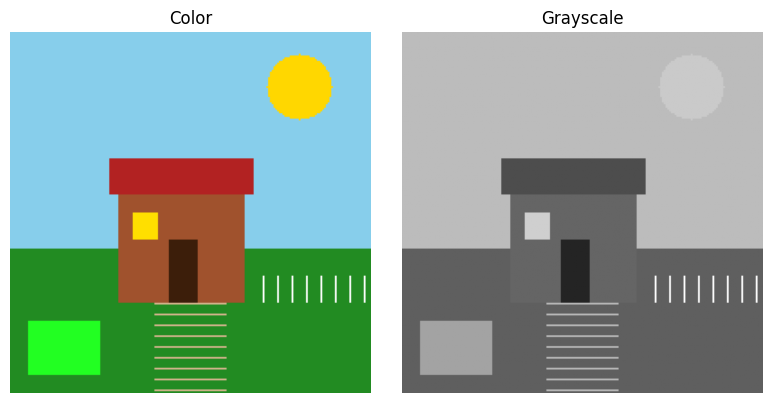

In [ ]:
# 1. Grayscale: weights reflect how the eye perceives R, G, B
weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)
gray = (scene.astype(np.float32) @ weights).astype(np.uint8)    # (200,200,3) @ (3,) -> (200,200)
print("Gray shape:", gray.shape)

# 2. Normalization to 0-1 floats, ready for a model
normalized = scene.astype(np.float32) / 255.0
print("Normalized range:", normalized.min(), "to", normalized.max())

# Standardization (zero mean, unit variance per channel), also very common
mean = normalized.mean(axis=(0, 1))
std = normalized.std(axis=(0, 1))
standardized = (normalized - mean) / std
print("Per-channel mean after standardizing:", standardized.mean(axis=(0, 1)).round(4))

show([scene, gray], ["Color", "Grayscale"], figsize=(8, 4))

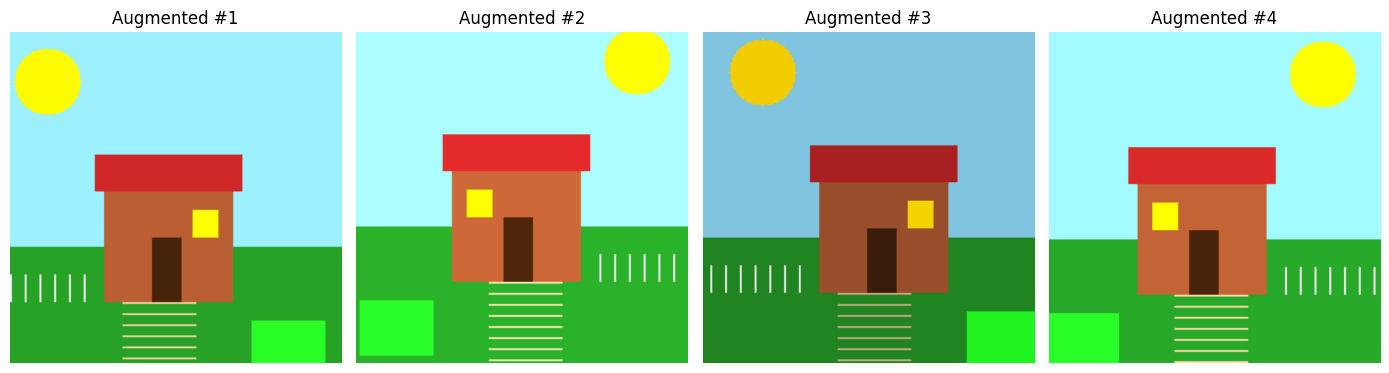

Batch shape: (4, 180, 180, 3)


In [ ]:
# 3. Data augmentation: generate varied versions of one image
def augment(image):
    out = image.copy()
    if np.random.rand() < 0.5:
        out = out[:, ::-1]                                   # random horizontal flip
    factor = np.random.uniform(0.7, 1.3)                     # random brightness
    out = np.clip(out.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    r = np.random.randint(0, 21); c = np.random.randint(0, 21)
    out = out[r:r + 180, c:c + 180]                          # random crop 180x180
    return out

batch = [augment(scene) for _ in range(4)]
show(batch, [f"Augmented #{i+1}" for i in range(4)], figsize=(14, 4))

# Stack into a batch array: (N, H, W, 3), the exact format ML libraries expect
batch_array = np.stack(batch)
print("Batch shape:", batch_array.shape)

## Summary
- Built images from scratch as `uint8` arrays with `np.zeros` and `np.full`
- Drew shapes and stripes with 3D slicing and a boolean circle mask
- Cropped, flipped (negative-step slicing), extracted channels and swapped them with fancy indexing
- Adjusted brightness safely with `astype(float32)` + `np.clip`, and showed why `uint8` overflow breaks naive math
- Used masks to find and recolor bright pixels
- Compared memory of `uint8` / `float32` / `float64` with `nbytes`
- Bonus ML prep: grayscale, normalization, standardization and augmentation

**Ideas to extend it:** add a blur filter with a sliding window, edge detection with a Sobel kernel, or load a real image with `plt.imread` and run the same functions on it.